# Classification

**Classification** is a type of supervised learning where the goal is to predict **discrete categories** (labels) instead of continuous values.

---
## Objective: 
By the end of this lab you will be able to:

1. Train and interpret four core classifiers using scikit-learn directly
2. Understand the effect of key hyperparameters on decision boundaries
3. Recognize bias-variance trade-offs from visual evidence
4. Evaluate models using classification reports and confusion matrices



----
## Types of Classification

- **Binary Classification**  
  Predicts **two possible outcomes** (e.g., positive vs negative).  
  - *Example:* Predict if a customer will **churn** or **stay**.

- **Multi-Class Classification**  
  Predicts **three or more mutually exclusive classes**.  
  - Categorize **news articles** into topics (politics, sports, tech)  
  - Classify **images of products** in an e-commerce platform  
  - Predict the **customer segment** based on behavior (low, medium, high value)

## Importance in Data Science

- Helps make **data-driven decisions**.  
- Automates tasks that involve **categorization**.  
- Enables applications like **fraud detection, medical diagnosis, and customer segmentation**.  
- Extracts **actionable insights** by identifying patterns in data.



> **Note on the `Dataset` class**  
> A `Dataset` helper is provided in `utils.py`. It loads a CSV, splits it into train/val/test sets, and reports class imbalance. You do **not** need to modify it 


# Setup

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from utils import Dataset
import mlflow
import warnings
warnings.filterwarnings('ignore')
import utils


# Part 1-  Linear Classification

Linear classification is a type of **supervised learning** where the model predicts categories by combining input features linearly and applying a **decision function**. It is widely used for both **binary** and **multi-class classification**.

---

## 1. Binary Linear Classification

In **binary classification**, the goal is to predict **two classes**.  

A common example is **Logistic Regression**, which uses the **sigmoid function** to output probabilities:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- Converts linear outputs into probabilities between 0 and 1  
- Thresholding at 0.5 gives class prediction (0 or 1)  

**Binary Cross-Entropy Loss** measures prediction error:

$$
L = -\frac{1}{N} \sum_{i=1}^{N} \big[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \big]
$$

$$
y_i = \text{true label (0 or 1)}, \quad \hat{y}_i = \text{predicted probability}
$$
 

The loss is minimized using **gradient descent** or optimizers like **Adam**, updating the model weights iteratively.

**Sigmoid Function Illustration:**  
![Sigmoid Function Placeholder](photos/sigmoid.png)



---

## 2. Multi-Class Linear Classification

For **multi-class classification** (3 or more classes), the **softmax function** generalizes sigmoid:

$$
\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}
$$

- Converts linear outputs into probabilities across all classes  
- Predicted class = the one with **highest probability**  

**Categorical Cross-Entropy Loss** is used:

$$
L = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} y_{i,k} \log(\hat{y}_{i,k})
$$


---

## 3. Linear Classification Workflow

**Step-by-step workflow:**

1. Compute linear combination of inputs:  

$$
z = w^T x + b
$$

2. Apply **activation function**:  
   - Sigmoid → binary  
   - Softmax → multi-class  

3. Compute **loss function**:  
   - Binary cross-entropy (binary)  
   - Categorical cross-entropy (multi-class)  

4. **Optimize weights** using gradient descent or advanced optimizers  



### Binary classification - Churn prediction

In [5]:
binary_churn_dataset=Dataset(filepath="../data/binary_churn.csv",
                                 target_column="Churn")


# As a sanity check, we print out the size of the training and test data.
print(f"Training data size: {binary_churn_dataset.X_train.shape[0]} samples")
print(f"Test data size: {binary_churn_dataset.X_test.shape[0]} samples")
print(f'Train label shape: {binary_churn_dataset.y_train.shape} ')
print(f'Test label shape: {binary_churn_dataset.y_test.shape} ')



Class Imbalance Ratio (IR): 1.11
Imbalance level: Mild (often OK with standard methods)
Training data size: 120 samples
Test data size: 40 samples
Train label shape: (120,) 
Test label shape: (40,) 


Question 1.1:
Why do we create 3 splits? Can we train on all data without splitting? Why or Why not? 
Your Answer: 

its splitted to 3 (training, validation and test), to use training set to train model, validation to tune hyperparameters and test should be new to the model to test its accuracy.

Question 1.2:
Suppose a student normalizes the entire dataset before splitting
Explain briefly:
- Is this an issue? Support your claim

by doing this, I am calculating or considering the 'future' data with me when calculating mean and other things, which isn't practical, so you should split first

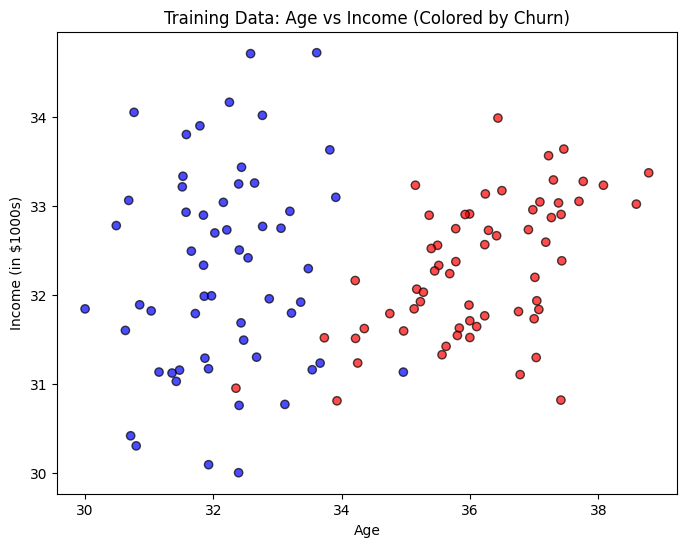

In [6]:
# Visualize the Dataset

plt.figure(figsize=(8, 6))
plt.scatter(
    binary_churn_dataset.X_train["Age"],
    binary_churn_dataset.X_train["Income (in $1000s)"],
    c=binary_churn_dataset.y_train,
    cmap="bwr",
    edgecolor="k",
    alpha=0.7
)
plt.xlabel("Age")
plt.ylabel("Income (in $1000s)")
plt.title("Training Data: Age vs Income (Colored by Churn)")
plt.show()

Train a binary Logistic Regression model

In [19]:
from sklearn.linear_model import LogisticRegression

# Step 1: Initialize the model with appropriate hyperparameters
logistic_model = LogisticRegression(
    random_state=42,
    max_iter = 200, 
    solver='lbfgs',
    penalty='l2',       # L2 regularization
    C=1000               # Inverse of regularization strength; smaller values specify stronger regularization
)

# Step 2: Fit the model on the training data
logistic_model.fit(binary_churn_dataset.X_train, binary_churn_dataset.y_train)



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1000
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` 

Question 1.3:
- What does `.fit` do? What is stored in the model after training? 

.fit trains the model by finding relationships between the features and label

after training, the model store the weights and bias required for prediction

Visualize the model

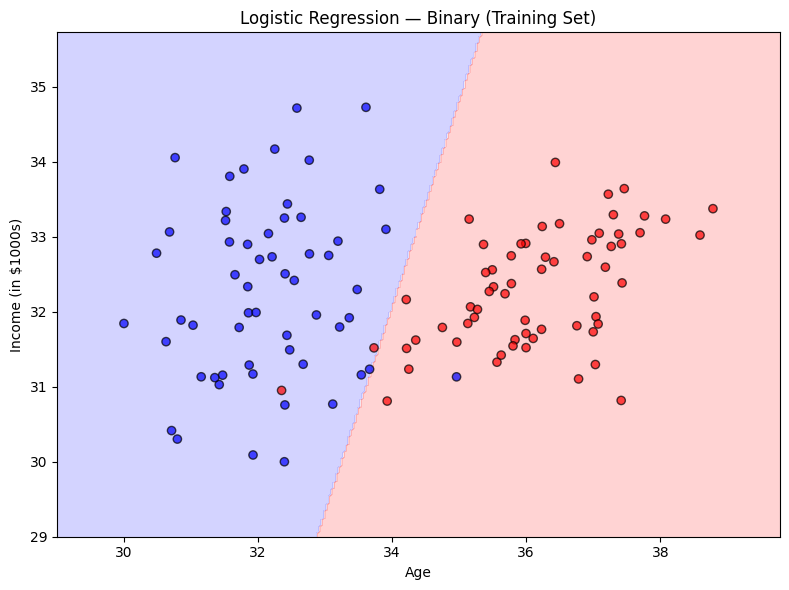

In [20]:
# Plot the decision boundary
utils.plot_decision_boundary(
    logistic_model,
    binary_churn_dataset.X_train.values,
    binary_churn_dataset.y_train.values,
    feature_names=["Age", "Income (in $1000s)"],
    title="Logistic Regression — Binary (Training Set)"
)

=== Evaluation ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



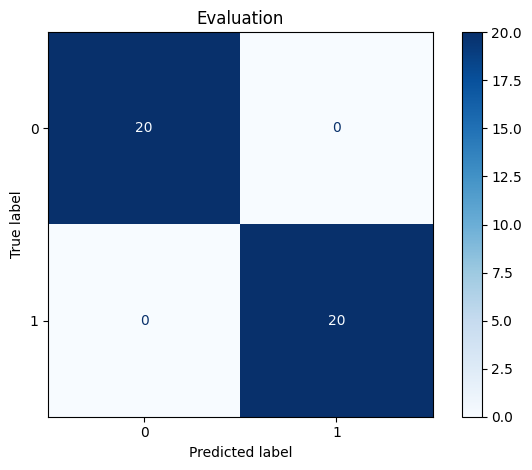

In [21]:
# Step 3: Validate the model
y_val_pred = utils.evaluate(logistic_model, binary_churn_dataset.X_val.values, binary_churn_dataset.y_val.values)

In [22]:
# Evaluate on the test set
y_test_pred = logistic_model.predict(binary_churn_dataset.X_test)
print("=== Test Set Performance ===")
print(classification_report(binary_churn_dataset.y_test, y_test_pred))


=== Test Set Performance ===
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        23
           1       0.94      1.00      0.97        17

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



Question 1.4:

What value of `C` did you choose and why?
What would happen to the decision boundary if you set `c` to 0.001 ? what about `C=1000`?
Your answer:

- best is C=1.0, achieved a better accuracy than when C=0.001 (flatter simpler curve)
- while C=1000 got same result as C=1.0, it could have introduced overfitting

### Multi class Classification - Customer Segments

Class Imbalance Ratio (IR): 1.08
Imbalance level: Mild (often OK with standard methods)


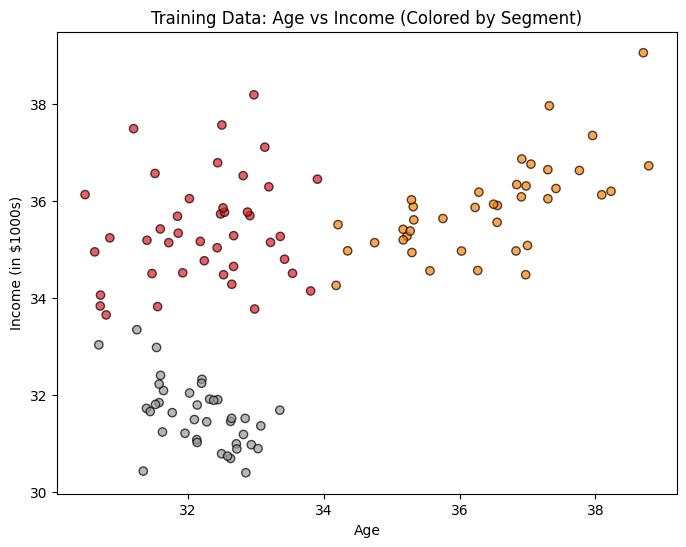

In [23]:
multiclass_dataset = Dataset(
    filepath="../data/customer_segments_churn.csv",
    target_column="Segment",
    random_state=55
)
# Uncomment the code below to visualize the multiclass dataset (colored by segment)
plt.figure(figsize=(8, 6))
plt.scatter(
    multiclass_dataset.X_train["Age"],
    multiclass_dataset.X_train["Income (in $1000s)"],
    c=multiclass_dataset.y_train,
    cmap="Set1",
    edgecolor="k",
    alpha=0.7
)
plt.xlabel("Age")
plt.ylabel("Income (in $1000s)")
plt.title("Training Data: Age vs Income (Colored by Segment)")
plt.show()

Train a multi class Logisitic regression
Use the same features Age and Incoome and the same hyperpameter choices. 
Sklean handles multi class automatically 

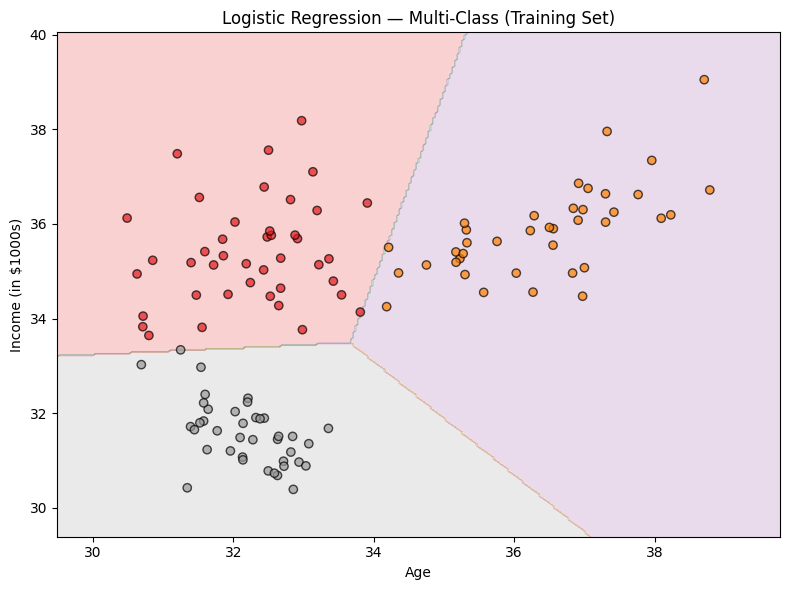

In [25]:
X_train_m = multiclass_dataset.X_train[["Age", "Income (in $1000s)"]].values
y_train_m = multiclass_dataset.y_train.values
X_val_m   = multiclass_dataset.X_val[["Age", "Income (in $1000s)"]].values
y_val_m   = multiclass_dataset.y_val.values

# TODO: Initialize and train a Logistic regression model for multiclass classification

logistic_multi = LogisticRegression(
    random_state=42,
    max_iter = 200, 
    solver='lbfgs',
    penalty='l2',       # L2 regularization
    C=1.0               # Inverse of regularization strength; smaller values specify stronger regularization
)
logistic_multi.fit(X_train_m, y_train_m)

utils.plot_decision_boundary(logistic_multi, X_train_m, y_train_m,
                       feature_names=["Age", "Income (in $1000s)"],
                       title="Logistic Regression — Multi-Class (Training Set)",
                       cmap='Set1')

=== Logistic Multi-Class — Validation ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.94      0.97        16
           2       1.00      1.00      1.00        14

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



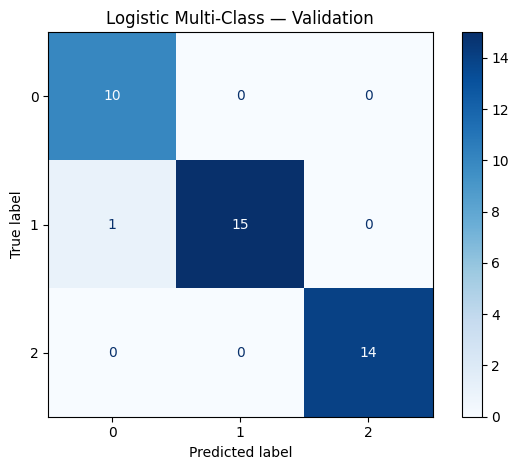

array([2, 0, 2, 2, 2, 0, 2, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 2, 2, 0, 1,
       0, 2, 0, 1, 2, 2, 2, 1, 2, 1, 2, 1, 1, 1, 1, 0, 0, 2])

In [26]:

utils.evaluate(logistic_multi, X_val_m, y_val_m, title="Logistic Multi-Class — Validation")


Question 1.5:
Look at the binary boundary vs. the multi-class boundary. Why is Logistic Regression constrained to produce **linear** decision boundaries? Under what data conditions would this be a fundamental limitation?

- the logisitic regression is essentialy a linear model with a threshold 
- difficult when data is not linearly separable / when there is non linear relationships  

# Part 2 - k-Nearest Neighbors (k-NN)

**k-Nearest Neighbors (k-NN)** is a simple **instance-based learning** method.  
It does not have an explicit training phase; instead, it **stores all training data** and makes predictions based on proximity to the stored points.

---

## 1. How k-NN Works

For any test instance:

1. **Find k closest training examples** using a distance metric (e.g., Euclidean distance).  
2. **For classification**: Take a **majority vote** among the k neighbors.  
3. **For probability estimation**: Compute the fraction of neighbors in each class.  

---

## 2. k-NN Variations

To improve efficiency and scalability:

- **Ball Tree / KD Tree**: Efficient spatial indexing for faster neighbor search.  
- **Approximate Nearest Neighbors**: Libraries like **FAISS** or **Annoy** trade some accuracy for speed.  
- **Reduce training set** (Prototype Selection / Condensing): Keep only a subset of **representative training points**.  

### Prototype Selection / Condensing Methods

- **Condensed Nearest Neighbor (CNN)**: Iteratively remove redundant points while keeping the decision boundary intact.  
- **Edited Nearest Neighbor (ENN)**: Remove noisy points that cause misclassification.  

**Benefit**: Smaller dataset → **faster predictions, less memory usage**.  
**Risk**: May lose some accuracy if important points are discarded.

In [27]:
# Reuse the multi class customer segments dataset
X_train_knn = multiclass_dataset.X_train[["Age", "Income (in $1000s)"]].values
y_train_knn = multiclass_dataset.y_train.values
X_val_knn   = multiclass_dataset.X_val[["Age", "Income (in $1000s)"]].values
y_val_knn   = multiclass_dataset.y_val.values

**TODO  — Train kNN with three different values of k**

Train three separate kNN classifiers with `k = 1`, `k = 5`, and `k = 20`.  
Use `algorithm='ball_tree'` for all three.  
Plot the decision boundary for each and evaluate on the validation set.


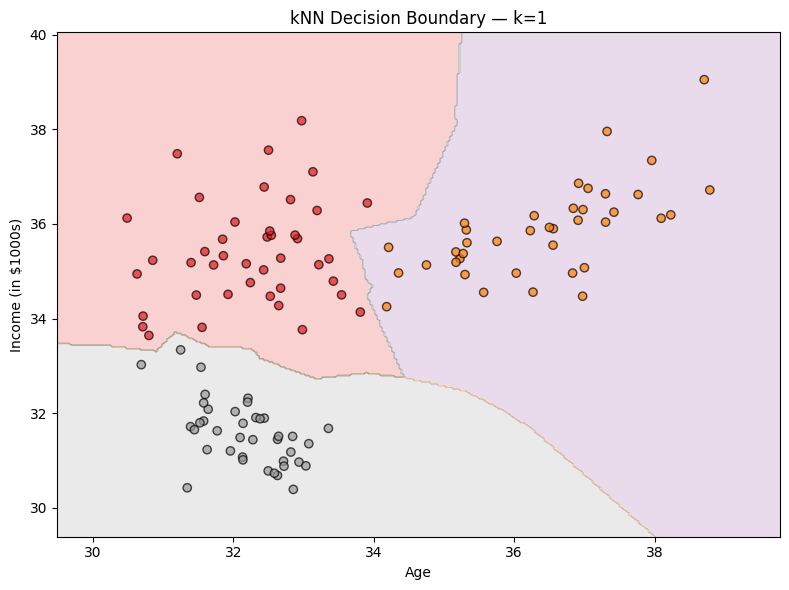

=== kNN k=1 — Validation ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.94      0.97        16
           2       1.00      1.00      1.00        14

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



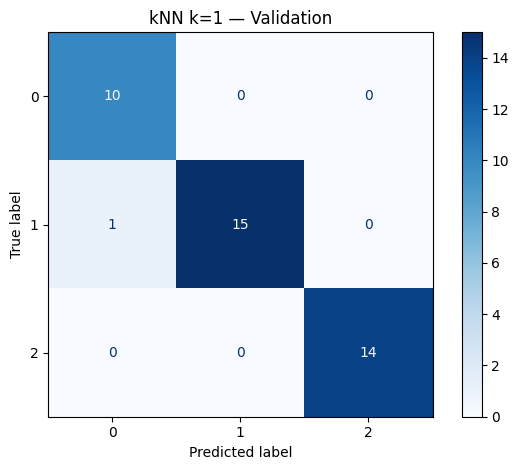

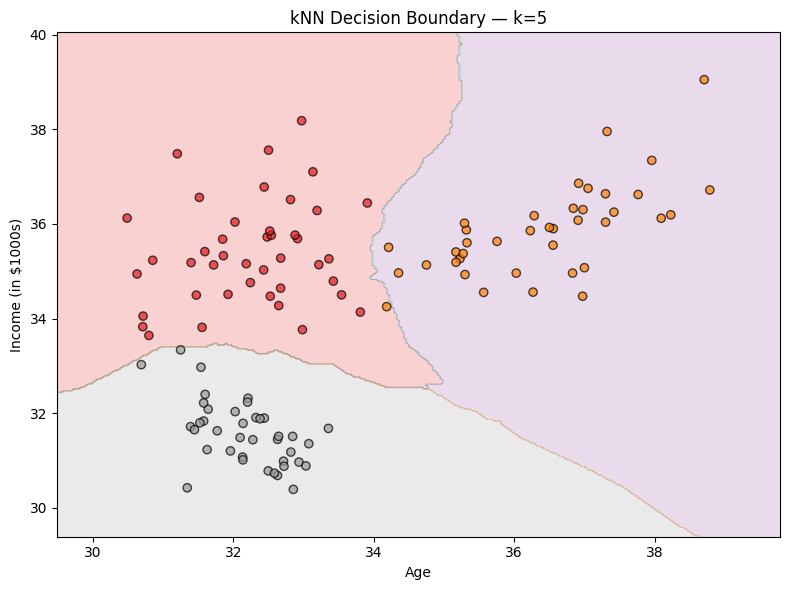

=== kNN k=5 — Validation ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.94      0.97        16
           2       1.00      1.00      1.00        14

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



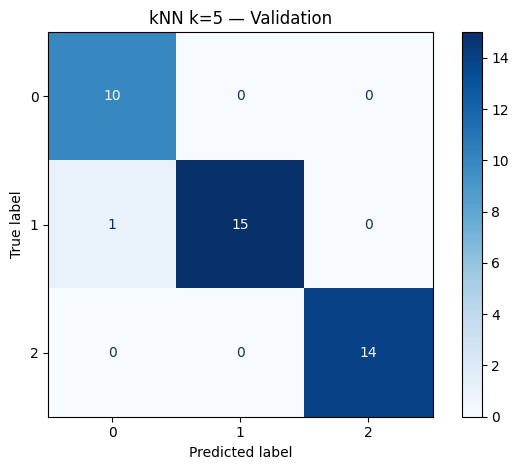

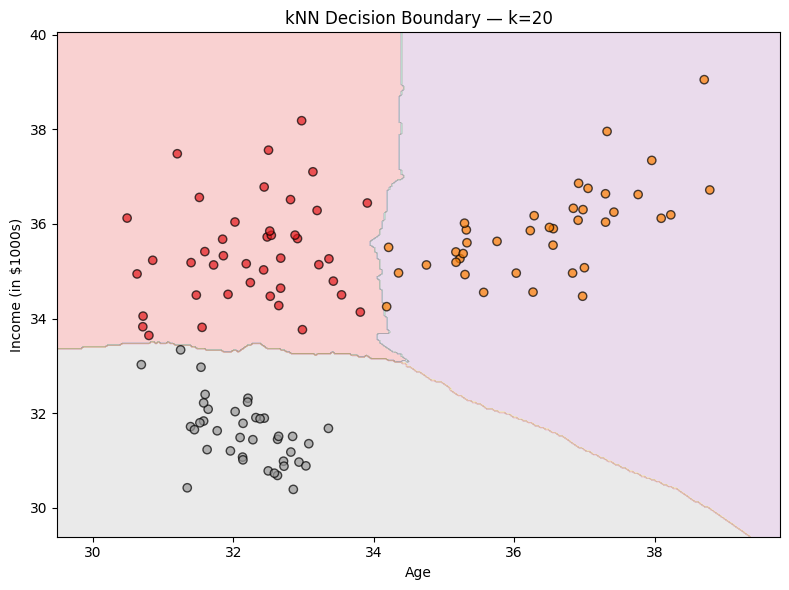

=== kNN k=20 — Validation ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.94      0.97        16
           2       1.00      1.00      1.00        14

    accuracy                           0.97        40
   macro avg       0.97      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



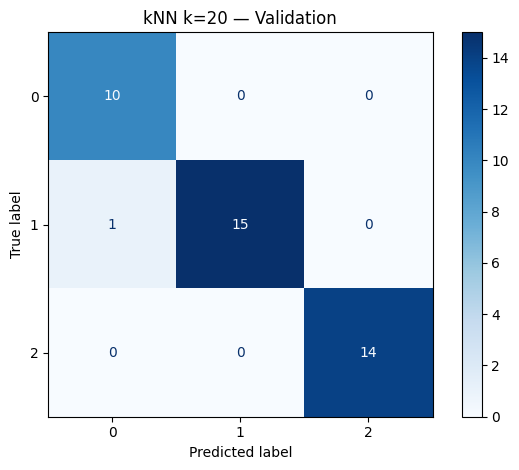

In [28]:
k_values = [1, 5, 20]

knn_models = {}

for k in k_values:
    # TODO: initialize KNeighborsClassifier with n_neighbors=k, algorithm='ball_tree'
    knn = KNeighborsClassifier(
        n_neighbors=k,
        algorithm='ball_tree'
    )  # replace with your model

    # TODO: fit the model
    # YOUR CODE HERE
    knn.fit(X_train_knn, y_train_knn)

    knn_models[k] = knn

    utils.plot_decision_boundary(knn, X_train_knn, y_train_knn,
                           feature_names=["Age", "Income (in $1000s)"],
                           title=f"kNN Decision Boundary — k={k}",
                           cmap='Set1')

    utils.evaluate(knn, X_val_knn, y_val_knn, title=f"kNN k={k} — Validation")


**Question 2.1 — Bias-Variance trade-off**
Compare the three decision boundaries. Describe what changes visually as k increases.
Which boundary looks overfit? Which looks underfit? How does this relate to bias and variance?

*Your answer here:*
--- 
as K increases, boundary becomes smoother

k=20 --> underfit && k=1 --> overfit

for higher Ks, bias increases and variance decrease, while for lower Ks, bias decreases and variance increases


**Question 2.2 — Choosing k in practice**
Based on your validation results above, which k would you choose and why?
What is the risk of choosing k based on test set performance instead of validation set performance?

*Your answer here:*
altho all produced same result, k=5 is the best choice, to avoid any risk of overfitting and underfitting

if K was chosen based on test set, it will be no longer 'new' data to the model and won't be good enough later

# Part 3 -  Support Vector Machine (SVM)

**Support Vector Machines (SVMs)** 
SVMs find the **maximum-margin hyperplane** — the decision boundary that is as far as possible from the nearest training points of each class. Those nearest points are called **support vectors**.

**Soft-margin SVM** (parameter C):  
Real data is rarely linearly separable. The parameter C controls the trade-off:

- High C → penalizes misclassifications heavily → tight margin, risk of overfitting  
- Low C → tolerates some misclassifications → wider margin, more generalizable

**The Kernel Trick:**  
For non-linearly separable data, SVMs map features into a higher-dimensional space using a **kernel function**, allowing a linear boundary in that space which corresponds to a non-linear boundary in the original space.

| Kernel | When to use |
|--------|-------------|
| `linear` | Data is approximately linearly separable |
| `rbf` | Default choice; works well for most problems |
| `poly` | When data has polynomial structure |

**Kernel SVM Illustration:**  
![Kernel SVM Placeholder](photos/kernel_trick.png)

**RBF kernel gamma (γ):**  
- High γ → each support vector has a **local** influence → wiggly boundary → overfitting risk  
- Low γ → each support vector has a **broad** influence → smoother boundary




Class Imbalance Ratio (IR): 1.02
Imbalance level: Mild (often OK with standard methods)


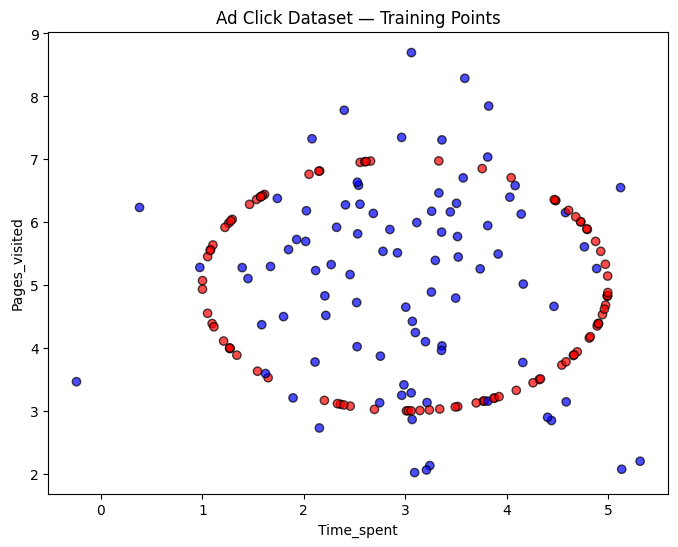

In [29]:
ad_click_dataset = Dataset(
    filepath="../data/ad_click.csv",
    target_column="Clicked_ad"
)
X_train_svm = ad_click_dataset.X_train[["Time_spent", "Pages_visited"]].values
y_train_svm = ad_click_dataset.y_train.values
X_val_svm   = ad_click_dataset.X_val[["Time_spent", "Pages_visited"]].values
y_val_svm   = ad_click_dataset.y_val.values

plt.figure(figsize=(8, 6))
plt.scatter(X_train_svm[:, 0], X_train_svm[:, 1], c=y_train_svm,
            cmap='bwr', edgecolor='k', alpha=0.7)
plt.xlabel("Time_spent")
plt.ylabel("Pages_visited")
plt.title("Ad Click Dataset — Training Points")
plt.show()

TODO: Train an SVM with a linear kernel

Start with a linear kernel to establish a baseline. Choose a value for `C`.


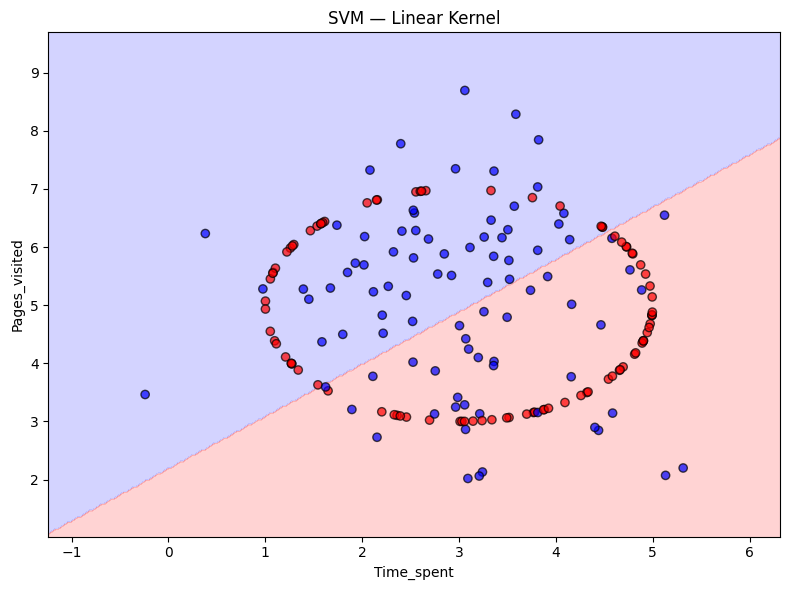

=== SVM Linear — Validation ===
              precision    recall  f1-score   support

           0       0.62      0.62      0.62        32
           1       0.57      0.57      0.57        28

    accuracy                           0.60        60
   macro avg       0.60      0.60      0.60        60
weighted avg       0.60      0.60      0.60        60



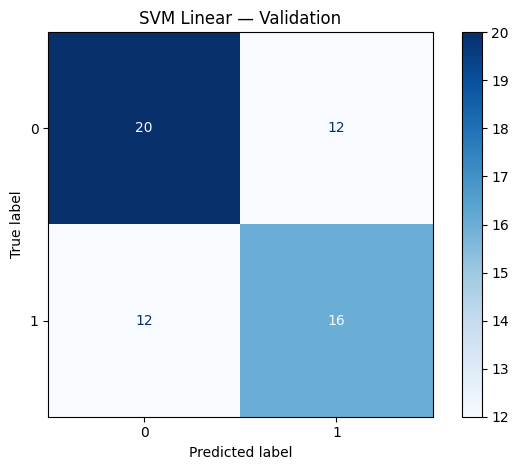

array([0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

In [30]:
# TODO: initialize SVC with kernel='linear', choose C, set probability=True
svm_linear = SVC(
    kernel='linear',
    C=1.0,
    probability=True
)  # replace with your model

# TODO: fit the model
# YOUR CODE HERE
svm_linear.fit(X_train_svm, y_train_svm)

utils.plot_decision_boundary(svm_linear, X_train_svm, y_train_svm,
                       feature_names=["Time_spent", "Pages_visited"],
                       title="SVM — Linear Kernel")

utils.evaluate(svm_linear, X_val_svm, y_val_svm, title="SVM Linear — Validation")


**TODO Train an SVM with an RBF kernel**

Now try the RBF kernel. Experiment with at least two combinations of `C` and `gamma`.


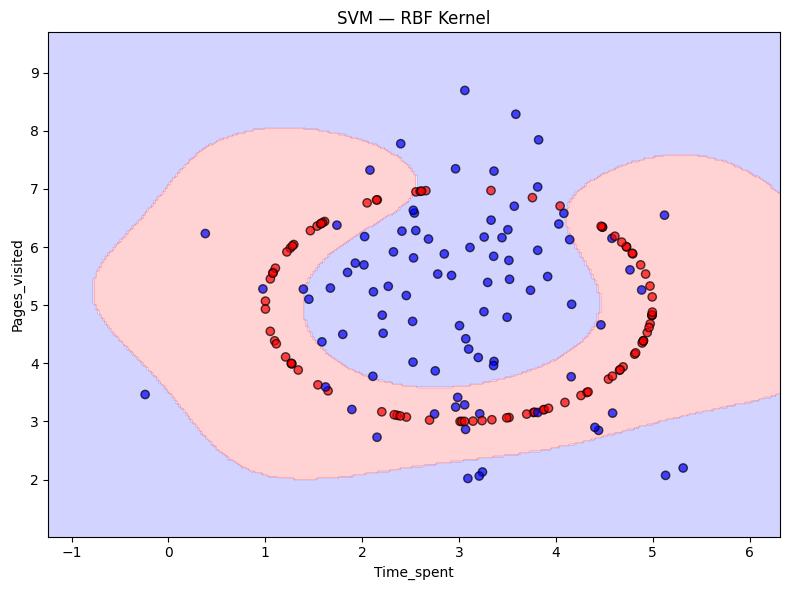

=== SVM RBF — Validation ===
              precision    recall  f1-score   support

           0       0.92      0.75      0.83        32
           1       0.76      0.93      0.84        28

    accuracy                           0.83        60
   macro avg       0.84      0.84      0.83        60
weighted avg       0.85      0.83      0.83        60



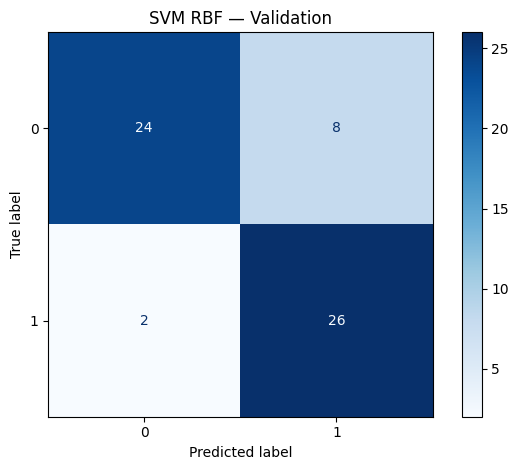

array([0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1])

In [31]:
# TODO: initialize SVC with kernel='rbf', choose C and gamma, set probability=True
svm_rbf = SVC(
    kernel='rbf',
    C=1.0,
    probability=True,
    gamma='auto'
)  # replace with your model

# TODO: fit the model
# YOUR CODE HERE
svm_rbf.fit(X_train_svm, y_train_svm)

utils.plot_decision_boundary(svm_rbf, X_train_svm, y_train_svm,
                       feature_names=["Time_spent", "Pages_visited"],
                       title="SVM — RBF Kernel")

utils.evaluate(svm_rbf, X_val_svm, y_val_svm, title="SVM RBF — Validation")


**Question 3.1 — Linear vs. RBF boundary**
Compare the two decision boundaries. What structural difference do you observe?
Why can the RBF kernel produce this kind of boundary while the linear kernel cannot?

*Your answer here:*
rbf was able to capture a more realistic boundary

rbf (non linear) can map datapoints into higher dimensional space to capture complex relation/structure

---


# Part 4:  Random Forest 


**Bagging (Bootstrap Aggregating)** reduces model variance by training many models on different random subsamples of the data and aggregating their predictions via majority vote.

**Random Forest** extends bagging by adding **random feature selection** at each split: instead of considering all features, each tree considers only a random subset. This **decorrelates** the trees, making the ensemble more robust.

Key hyperparameters:

| Parameter | Effect |
|-----------|--------|
| `n_estimators` | More trees → more stable predictions, diminishing returns |
| `max_depth` | Deeper trees → more complex, risk of overfitting |
| `max_features` | Fraction of features per split; lower = more decorrelated trees |

**Grid Search** is a systematic way to find good hyperparameters: you define a grid of values and train/evaluate the model at every combination using cross-validation.
**Random Forest Illustration:**  
![Random Forest Placeholder](photos/random-forest.png)


In [32]:
# Reuse the ad_click dataset
X_train_rf = ad_click_dataset.X_train.values
y_train_rf = ad_click_dataset.y_train.values
X_val_rf   = ad_click_dataset.X_val.values
y_val_rf   = ad_click_dataset.y_val.values


**Question 4.1 — Grid design rationale** *(answer before writing any code)*

- Why would trying `max_depth=100` be a bad idea for a Random Forest?
- Why does adding more estimators beyond a certain point stop helping?

*Your answer here:*
- may cause overfitting
- redundant and will eventually converge

**TODO 4.1 — Run a grid search to find the best Random Forest configuration**

In [33]:

param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [3, 5, 7, 10]
}

# TODO: initialize a RandomForestClassifier (base model for grid search)
rf_base = RandomForestClassifier()

# TODO: initialize GridSearchCV with 5-fold CV, scoring='accuracy'
grid_search = GridSearchCV(rf_base, param_grid, cv=5, scoring='accuracy')  # replace with your GridSearchCV


# TODO: fit the grid search on training data
# YOUR CODE HERE
# rf_base.fit(X_train_rf, y_train_rf)
grid_search.fit(X_train_rf, y_train_rf)

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)



Best parameters: {'max_depth': 7, 'n_estimators': 50}
Best CV accuracy: 0.888888888888889


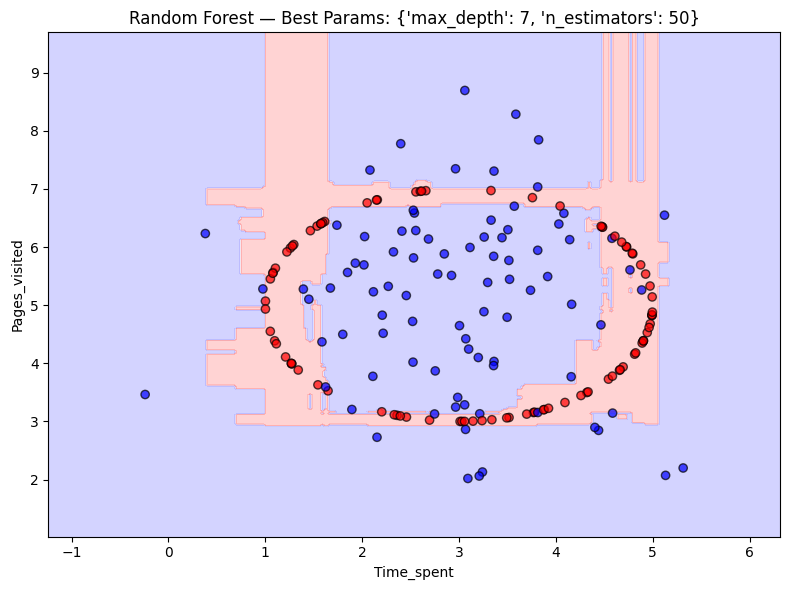

=== Random Forest — Validation ===
              precision    recall  f1-score   support

           0       0.81      0.78      0.79        32
           1       0.76      0.79      0.77        28

    accuracy                           0.78        60
   macro avg       0.78      0.78      0.78        60
weighted avg       0.78      0.78      0.78        60



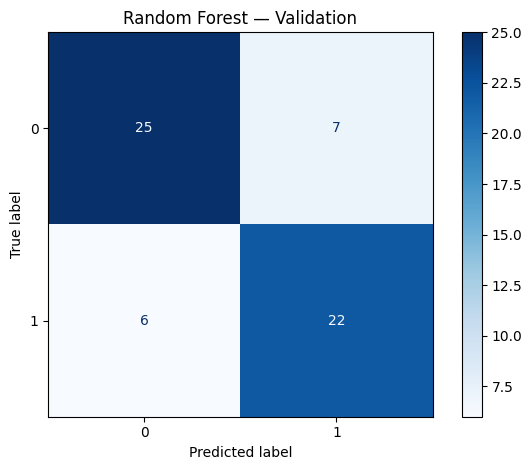

array([0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1])

In [34]:
# Use the best estimator from grid search
best_rf = grid_search.best_estimator_

X_train_rf_2d = ad_click_dataset.X_train[["Time_spent", "Pages_visited"]].values
y_train_rf_2d = ad_click_dataset.y_train.values

# Refit on 2D for visualization only
best_rf_2d = RandomForestClassifier(**grid_search.best_params_, random_state=42)
best_rf_2d.fit(X_train_rf_2d, y_train_rf_2d)

utils.plot_decision_boundary(best_rf_2d, X_train_rf_2d, y_train_rf_2d,
                       feature_names=["Time_spent", "Pages_visited"],
                       title=f"Random Forest — Best Params: {grid_search.best_params_}",
                       cmap='bwr')

# Evaluate the full model (all features) on validation set
utils.evaluate(best_rf, X_val_rf, y_val_rf, title="Random Forest — Validation")



**TODO — Feature importance**

Random Forest provides built-in feature importance scores. Extract and plot them.


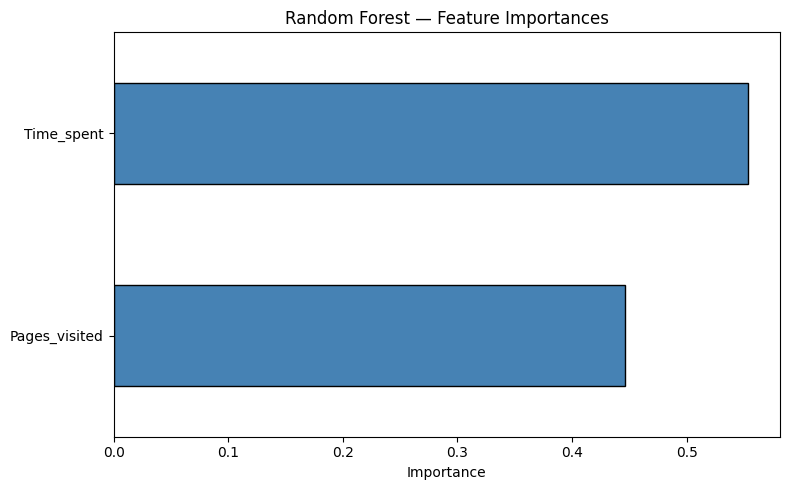

In [39]:
feature_names = ad_click_dataset.X_train.columns.tolist()

# TODO: extract feature importances from best_rf and plot a bar chart
# Hint - use best_rf.feature_importances_ to get importance scores

importances = best_rf.feature_importances_
# Your code here
import pandas as pd
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
feat_imp.plot(kind='barh', ax=ax, color="steelblue", edgecolor="k")
ax.set_xlabel("Importance")
ax.set_title("Random Forest — Feature Importances")
plt.tight_layout()
plt.show()

# References

- [scikit-learn](https://scikit-learn.org/) – Machine learning library for Python  
- [XGBoost](https://xgboost.readthedocs.io/) – Gradient boosting library for structured/tabular data  
- [Matplotlib](https://matplotlib.org/) – Plotting and visualization library  
- [Pandas](https://pandas.pydata.org/) – Data manipulation and analysis library  
- [NumPy](https://numpy.org/) – Numerical computing library  
- [Imbalanced-learn](https://imbalanced-learn.org/) – Library for handling class imbalance in datasets
